# Planet Sandbox: Analysis-Ready PlanetScope (Pará, Brazil) via Sentinel Hub

**Why the earlier notebook failed (404):** this sandbox collection (`byoc-3f605f75-86c4-411a-b4ae-01c896f0e54e`, source `PS_ARD_SR_DAILY`) is hosted on **Sentinel Hub** (`services.sentinel-hub.com`), not on `api.planet.com`. Planet API keys only work with `api.planet.com`, and the `/data/collections/v2/...` path does not exist there.

**What this notebook does differently**
- Authenticates with an **OAuth client ID + secret** (not the API key).
- Searches with the Sentinel Hub **Catalog API**.
- Downloads a GeoTIFF with the **Process API**. There is no asset activation step.
- Then shows an RGB preview and NDVI.

**Before running (one time):**
1. Open the Planet Account app: <https://insights.planet.com/account/#/> → **OAuth Clients** → **Create New**.
2. Copy the **client ID** and **client secret** immediately (the secret is shown only once).
3. Your account needs Monitoring Credits (paid or trial). The sandbox data is CC-BY-NC.

The collection covers **2021-01-01 to 2023-12-29** over a 576 km² area centered near (-6.77, -52.38). Requests consume Processing Units from your account.

Never paste your secret into a shared notebook. It is requested with `getpass` below.

## 1. Install packages

In [12]:
#%pip install requests pandas rasterio matplotlib numpy

## 2. Imports

In [13]:
import json
import time
from pathlib import Path
from getpass import getpass

import numpy as np
import pandas as pd
import requests

## 3. Settings

In [14]:
COLLECTION_ID = "3f605f75-86c4-411a-b4ae-01c896f0e54e"
COLLECTION = f"byoc-{COLLECTION_ID}"

# Area of interest: [west, south, east, north] in EPSG:4326
BBOX = [-52.4825, -6.8735, -52.26725, -6.65775]

# Must fall inside 2021-01-01 .. 2023-12-29
START_DATE = "2013-01-01T00:00:00Z"
END_DATE = "2026-01-31T23:59:59Z"

# Output size in pixels (Process API maximum is 2500 x 2500).
# 2400 px over ~24 km is ~10 m per pixel. The native resolution is 3 m,
# so use a smaller BBOX if you want full resolution.
WIDTH = 2400
HEIGHT = 2400

# Sentinel Hub deployment. The Planet sandbox is normally on the EU one.
# If auth or search says the collection does not exist, try the US one:
#   "https://services-uswest2.sentinel-hub.com"
BASE_URL = "https://services.sentinel-hub.com"

print("Collection:", COLLECTION)
print("Date range:", START_DATE, "to", END_DATE)

Collection: byoc-3f605f75-86c4-411a-b4ae-01c896f0e54e
Date range: 2013-01-01T00:00:00Z to 2026-01-31T23:59:59Z


## 4. Enter your OAuth client credentials (private)

In [15]:
CLIENT_ID = getpass("Planet OAuth client ID: ").strip()
CLIENT_SECRET = getpass("Planet OAuth client secret: ").strip()

if not CLIENT_ID or not CLIENT_SECRET:
    raise RuntimeError("Client ID and secret are both required.")

print("Credentials loaded.")

Credentials loaded.


## 5. Get an access token (cached and refreshed automatically)

In [16]:
_token = {"value": None, "expires_at": 0.0}


def get_token():
    """Return a valid bearer token, fetching a new one only when needed."""
    if _token["value"] and time.time() < _token["expires_at"] - 60:
        return _token["value"]

    r = requests.post(
        f"{BASE_URL}/auth/realms/main/protocol/openid-connect/token",
        data={
            "grant_type": "client_credentials",
            "client_id": CLIENT_ID,
            "client_secret": CLIENT_SECRET,
        },
        timeout=60,
    )

    if not r.ok:
        print("Token request failed:", r.status_code)
        print(r.text[:1000])
        r.raise_for_status()

    data = r.json()
    _token["value"] = data["access_token"]
    _token["expires_at"] = time.time() + int(data.get("expires_in", 3600))
    return _token["value"]


def auth_headers(**extra):
    return {"Authorization": f"Bearer {get_token()}", **extra}


get_token()
print("Authentication succeeded.")

Authentication succeeded.


## 6. Search the Catalog API
Lists the dates that have imagery over your AOI.

In [17]:
def catalog_search(body):
    # Try the documented catalog paths in turn (they are aliases of each other).
    last = None
    for path in ("/api/v1/catalog/1.0.0/search", "/catalog/v1/search"):
        r = requests.post(
            BASE_URL + path,
            headers=auth_headers(**{"Content-Type": "application/json"}),
            json=body,
            timeout=120,
        )
        if r.status_code != 404:
            return r
        last = r
    return last


body = {
    "collections": [COLLECTION],
    "bbox": BBOX,
    "datetime": f"{START_DATE}/{END_DATE}",
    "limit": 100,
}

features = []

for page in range(20):
    r = catalog_search(body)

    if not r.ok:
        print("HTTP status:", r.status_code)
        print(r.text[:2000])
        if r.status_code == 401:
            print("-> Credentials rejected. Check client ID/secret.")
        elif r.status_code == 403:
            print("-> Account may lack access/Monitoring Credits for this collection.")
        elif r.status_code == 404:
            print("-> Try the other deployment (BASE_URL in Cell 3).")
        r.raise_for_status()

    result = r.json()
    features.extend(result.get("features", []))

    nxt = result.get("context", {}).get("next")
    if not nxt:
        break
    body["next"] = nxt

print("Returned features:", len(features))

if not features:
    print("No scenes found. The collection covers 2021-01-01 to 2023-12-29; "
          "check START_DATE/END_DATE and that BBOX is inside the sandbox area.")

Returned features: 677


## 7. Inspect results

In [18]:
if not features:
    raise RuntimeError("No scenes found. See the message above.")

print("Properties available on the first feature:")
print(json.dumps(features[0].get("properties", {}), indent=2)[:1500])

rows = []
for f in features:
    p = f.get("properties", {})
    row = {"id": f.get("id"), "datetime": p.get("datetime")}
    for k, v in p.items():
        if "cloud" in k.lower():
            row[k] = v
    rows.append(row)

results_df = pd.DataFrame(rows)
results_df["date"] = results_df["datetime"].str[:10]
display(results_df.head(30))

print("\nDates with data:", sorted(results_df["date"].unique()))

Properties available on the first feature:
{
  "datetime": "2023-12-29T00:00:00Z",
  "proj:epsg": 32722,
  "proj:bbox": [
    336000.0,
    9240000.0,
    360000.0,
    9264000.0
  ],
  "proj:geometry": {
    "type": "Polygon",
    "crs": {
      "type": "name",
      "properties": {
        "name": "urn:ogc:def:crs:EPSG::32722"
      }
    },
    "coordinates": [
      [
        [
          336000.00000084564,
          9240000.00000001
        ],
        [
          360000.00000031735,
          9240000.000000002
        ],
        [
          360000.0000003204,
          9264000.000000002
        ],
        [
          336000.00000085135,
          9264000.00000001
        ],
        [
          336000.00000084564,
          9240000.00000001
        ]
      ]
    ]
  }
}


,id,datetime,date
0,4fd3e6eb-1f6d-458a-bbae-79d66b583302,2023-12-29T00:00:00Z,2023-12-29
1,0792c687-c0f3-4c96-8080-1394cafe91ad,2023-12-28T00:00:00Z,2023-12-28
2,84298261-298a-46be-8ca3-b7ca814a48ea,2023-12-25T00:00:00Z,2023-12-25
3,b5658ba1-25c9-4f26-b057-ad096dab02a7,2023-12-20T00:00:00Z,2023-12-20
4,c521fc07-d467-486d-b95b-584856955cf1,2023-12-19T00:00:00Z,2023-12-19
5,4f92ec3f-df19-4c4d-a42d-d82aab42297c,2023-12-16T00:00:00Z,2023-12-16
6,e74712b2-5424-4115-b785-0bbb1833ec4b,2023-12-15T00:00:00Z,2023-12-15
7,4953a8f0-d1f7-4bd5-9b3d-d95d43ae2de5,2023-12-14T00:00:00Z,2023-12-14
8,8663ed59-1b2a-4c47-a181-49274d9fd961,2023-12-13T00:00:00Z,2023-12-13
9,48e44399-d92a-41c2-af78-e479a55a76bd,2023-12-08T00:00:00Z,2023-12-08



Dates with data: ['2021-01-01', '2021-01-02', '2021-01-05', '2021-01-06', '2021-01-07', '2021-01-08', '2021-01-18', '2021-01-22', '2021-01-26', '2021-01-27', '2021-02-01', '2021-02-02', '2021-02-03', '2021-02-07', '2021-02-24', '2021-03-05', '2021-03-15', '2021-03-16', '2021-03-20', '2021-03-21', '2021-03-23', '2021-03-24', '2021-03-26', '2021-03-27', '2021-03-29', '2021-03-30', '2021-04-03', '2021-04-04', '2021-04-07', '2021-04-08', '2021-04-09', '2021-04-11', '2021-04-12', '2021-04-13', '2021-04-14', '2021-04-15', '2021-04-16', '2021-04-24', '2021-04-25', '2021-04-26', '2021-04-29', '2021-05-02', '2021-05-03', '2021-05-04', '2021-05-06', '2021-05-08', '2021-05-10', '2021-05-11', '2021-05-12', '2021-05-13', '2021-05-15', '2021-05-16', '2021-05-17', '2021-05-20', '2021-05-21', '2021-05-22', '2021-05-23', '2021-05-24', '2021-05-25', '2021-05-26', '2021-05-27', '2021-05-28', '2021-05-29', '2021-05-30', '2021-05-31', '2021-06-01', '2021-06-02', '2021-06-03', '2021-06-04', '2021-06-05', '

In [19]:
results_df.to_csv("all_images_sentinel.csv", index=False)

## 8. Choose a date
By default this picks the date with the lowest cloud cover (if the catalog reports it), otherwise the first date. Override `SELECTED_DATE` to pick your own, e.g. `"2022-01-14"`.

In [20]:
SELECTED_DATE = None  # e.g. "2022-01-14"

cloud_cols = [c for c in results_df.columns if "cloud" in c.lower()]

if SELECTED_DATE is None:
    if cloud_cols:
        per_date = results_df.groupby("date")[cloud_cols[0]].mean().sort_values()
        SELECTED_DATE = per_date.index[0]
        print(f"Lowest mean {cloud_cols[0]}:", round(float(per_date.iloc[0]), 2))
    else:
        SELECTED_DATE = sorted(results_df["date"].unique())[0]

print("Selected date:", SELECTED_DATE)

Selected date: 2021-01-01


## 9. Download a GeoTIFF with the Process API
Tries the standard 4-band surface-reflectance band names first, then the 8-band names. `dataMask` is added as an extra last band (1 = valid pixel).

In [21]:
""" 
CANDIDATE_BANDS = [
    ["blue", "green", "red", "nir"],
    ["blue", "green", "red", "nir", "rededge"],
    ["coastal_blue", "blue", "green_i", "green", "yellow", "red", "rededge", "nir"],
]


def build_evalscript(bands):
    inputs = ", ".join(f'"{b}"' for b in bands + ["dataMask"])
    returns = ", ".join(f"s.{b}" for b in bands + ["dataMask"])
#    return f### //VERSION=3
function setup() {{
  return {{
    input: [{{ bands: [{inputs}] }}],
    output: {{ bands: {len(bands) + 1}, sampleType: "FLOAT32" }}
  }};
}}
function evaluatePixel(s) {{
  return [{returns}];
}}
###


def process_request(bands):
    payload = {
        "input": {
            "bounds": {
                "bbox": BBOX,
                "properties": {"crs": "http://www.opengis.net/def/crs/EPSG/0/4326"},
            },
            "data": [{
                "type": COLLECTION,
                "dataFilter": {
                    "timeRange": {
                        "from": f"{SELECTED_DATE}T00:00:00Z",
                        "to": f"{SELECTED_DATE}T23:59:59Z",
                    },
                    "mosaickingOrder": "mostRecent",
                },
            }],
        },
        "output": {
            "width": WIDTH,
            "height": HEIGHT,
            "responses": [{"identifier": "default", "format": {"type": "image/tiff"}}],
        },
        "evalscript": build_evalscript(bands),
    }
    return requests.post(
        f"{BASE_URL}/api/v1/process",
        headers=auth_headers(**{"Content-Type": "application/json", "Accept": "image/tiff"}),
        json=payload,
        timeout=600,
    )


OUTPUT_DIR = Path("planet_downloads")
OUTPUT_DIR.mkdir(exist_ok=True)
output_file = OUTPUT_DIR / f"ARPS_Para_{SELECTED_DATE}.tif"

used_bands = None

for bands in CANDIDATE_BANDS:
    print("Trying bands:", bands)
    r = process_request(bands)
    print("  HTTP status:", r.status_code)

    if r.ok:
        output_file.write_bytes(r.content)
        used_bands = bands
        break

    print("  ", r.text[:600])
    if r.status_code in (401, 403, 429):
        r.raise_for_status()

if used_bands is None:
    raise RuntimeError(
        "All band sets failed. Read the error text above: it usually names "
        "the invalid band or the access problem. Set CANDIDATE_BANDS to the "
        "band names it reports."
    )

print("Saved:", output_file)
print("File size:", f"{output_file.stat().st_size:,}", "bytes")
print("Bands in file:", used_bands + ["dataMask"])

"""

' \nCANDIDATE_BANDS = [\n    ["blue", "green", "red", "nir"],\n    ["blue", "green", "red", "nir", "rededge"],\n    ["coastal_blue", "blue", "green_i", "green", "yellow", "red", "rededge", "nir"],\n]\n\n\ndef build_evalscript(bands):\n    inputs = ", ".join(f\'"{b}"\' for b in bands + ["dataMask"])\n    returns = ", ".join(f"s.{b}" for b in bands + ["dataMask"])\n#    return f### //VERSION=3\nfunction setup() {{\n  return {{\n    input: [{{ bands: [{inputs}] }}],\n    output: {{ bands: {len(bands) + 1}, sampleType: "FLOAT32" }}\n  }};\n}}\nfunction evaluatePixel(s) {{\n  return [{returns}];\n}}\n###\n\n\ndef process_request(bands):\n    payload = {\n        "input": {\n            "bounds": {\n                "bbox": BBOX,\n                "properties": {"crs": "http://www.opengis.net/def/crs/EPSG/0/4326"},\n            },\n            "data": [{\n                "type": COLLECTION,\n                "dataFilter": {\n                    "timeRange": {\n                        "from": f"

## b) Download every 41st date, always including the first and last

In [22]:
STEP = 4

# "Pictures" = acquisition dates found by the Catalog search (Cell 6/7)
all_dates = sorted(results_df["date"].unique())

picked = all_dates[::STEP]
if all_dates[-1] not in picked:      # always include the last one
    picked.append(all_dates[-1])

print(f"{len(all_dates)} dates found -> downloading {len(picked)}:")
print(picked)

_saved_date, _saved_file = SELECTED_DATE, output_file
downloaded, failed = [], []

for d in picked:
    out = OUTPUT_DIR / f"ARPS_Para_{d}.tif"

    if out.exists() and out.stat().st_size > 0:
        print(d, "- already downloaded, skipping")
        downloaded.append(out)
        continue

    SELECTED_DATE = d                       # process_request() reads this global
    r = process_request(used_bands)         # band set that worked in Cell 9

    if r.ok:
        out.write_bytes(r.content)
        downloaded.append(out)
        print(d, "- saved", f"{out.stat().st_size:,}", "bytes")
    else:
        failed.append(d)
        print(d, "- FAILED", r.status_code, r.text[:200])
        if r.status_code in (401, 403, 429):
            break                           # auth/quota problem: stop early

    time.sleep(1)                           # be gentle with rate limits

SELECTED_DATE, output_file = _saved_date, _saved_file   # restore for later cells

print(f"\nDone: {len(downloaded)} downloaded, {len(failed)} failed")
if failed:
    print("Failed dates:", failed)

677 dates found -> downloading 170:
['2021-01-01', '2021-01-07', '2021-01-26', '2021-02-03', '2021-03-15', '2021-03-23', '2021-03-29', '2021-04-07', '2021-04-12', '2021-04-16', '2021-04-29', '2021-05-06', '2021-05-12', '2021-05-17', '2021-05-23', '2021-05-27', '2021-05-31', '2021-06-04', '2021-06-08', '2021-06-12', '2021-06-17', '2021-06-21', '2021-06-25', '2021-06-29', '2021-07-04', '2021-07-08', '2021-07-12', '2021-07-16', '2021-07-20', '2021-07-24', '2021-07-28', '2021-08-01', '2021-08-05', '2021-08-09', '2021-08-13', '2021-08-17', '2021-08-21', '2021-08-25', '2021-08-30', '2021-09-06', '2021-09-10', '2021-09-14', '2021-09-18', '2021-09-22', '2021-09-27', '2021-10-01', '2021-10-05', '2021-10-10', '2021-10-17', '2021-10-24', '2021-10-29', '2021-11-03', '2021-11-13', '2021-11-22', '2021-11-27', '2021-12-05', '2021-12-19', '2022-01-14', '2022-01-20', '2022-01-26', '2022-02-08', '2022-02-22', '2022-02-27', '2022-03-12', '2022-03-22', '2022-04-02', '2022-04-09', '2022-04-15', '2022-04-26

NameError: name 'output_file' is not defined

## 10. Read the GeoTIFF

In [ ]:
""" #for a single image not all of them
 import rasterio

with rasterio.open(output_file) as src:
    print("Driver:", src.driver)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Resolution:", src.res)
    print("Data type:", src.dtypes)
    image = src.read()

band_index = {name: i for i, name in enumerate(used_bands + ["dataMask"])}
valid = image[band_index["dataMask"]] > 0

print("Array shape:", image.shape)
print("Valid pixels:", f"{valid.mean():.1%}")

"""

' #for a single image not all of them\n import rasterio\n\nwith rasterio.open(output_file) as src:\n    print("Driver:", src.driver)\n    print("Width:", src.width)\n    print("Height:", src.height)\n    print("Bands:", src.count)\n    print("CRS:", src.crs)\n    print("Bounds:", src.bounds)\n    print("Resolution:", src.res)\n    print("Data type:", src.dtypes)\n    image = src.read()\n\nband_index = {name: i for i, name in enumerate(used_bands + ["dataMask"])}\nvalid = image[band_index["dataMask"]] > 0\n\nprint("Array shape:", image.shape)\nprint("Valid pixels:", f"{valid.mean():.1%}")\n\n'

## 11. Display the image (true color)

In [ ]:
""" #for a single image not all of them
import matplotlib.pyplot as plt


def scale_band(band, mask):
    band = band.astype("float32")
    ok = np.isfinite(band) & mask

    if not ok.any():
        return np.zeros_like(band, dtype="float32")

    low, high = np.percentile(band[ok], [2, 98])

    if high <= low:
        return np.zeros_like(band, dtype="float32")

    out = np.clip((band - low) / (high - low), 0, 1)
    out[~mask] = 0
    return out


red = scale_band(image[band_index["red"]], valid)
green = scale_band(image[band_index["green"]], valid)
blue = scale_band(image[band_index["blue"]], valid)

plt.figure(figsize=(10, 8))
plt.imshow(np.dstack([red, green, blue]))
plt.title(f"Analysis-Ready PlanetScope, Para - {SELECTED_DATE} (RGB)")
plt.axis("off")
plt.show()

"""


' #for a single image not all of them\nimport matplotlib.pyplot as plt\n\n\ndef scale_band(band, mask):\n    band = band.astype("float32")\n    ok = np.isfinite(band) & mask\n\n    if not ok.any():\n        return np.zeros_like(band, dtype="float32")\n\n    low, high = np.percentile(band[ok], [2, 98])\n\n    if high <= low:\n        return np.zeros_like(band, dtype="float32")\n\n    out = np.clip((band - low) / (high - low), 0, 1)\n    out[~mask] = 0\n    return out\n\n\nred = scale_band(image[band_index["red"]], valid)\ngreen = scale_band(image[band_index["green"]], valid)\nblue = scale_band(image[band_index["blue"]], valid)\n\nplt.figure(figsize=(10, 8))\nplt.imshow(np.dstack([red, green, blue]))\nplt.title(f"Analysis-Ready PlanetScope, Para - {SELECTED_DATE} (RGB)")\nplt.axis("off")\nplt.show()\n\n'

## 12. NDVI
NDVI is a ratio, so it does not depend on whether the reflectance values are scaled (the documented ARPS scale is DN/10000).

In [ ]:
"""#for a single image not all of them

red_b = image[band_index["red"]].astype("float32")
nir_b = image[band_index["nir"]].astype("float32")
den = nir_b + red_b

ndvi = np.where((den != 0) & valid, (nir_b - red_b) / den, np.nan)

print("NDVI minimum:", np.nanmin(ndvi))
print("NDVI maximum:", np.nanmax(ndvi))
print("NDVI mean:", np.nanmean(ndvi))

plt.figure(figsize=(10, 8))
plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDVI")
plt.title(f"NDVI - {SELECTED_DATE}")
plt.axis("off")
plt.show()

"""

'#for a single image not all of them\n\nred_b = image[band_index["red"]].astype("float32")\nnir_b = image[band_index["nir"]].astype("float32")\nden = nir_b + red_b\n\nndvi = np.where((den != 0) & valid, (nir_b - red_b) / den, np.nan)\n\nprint("NDVI minimum:", np.nanmin(ndvi))\nprint("NDVI maximum:", np.nanmax(ndvi))\nprint("NDVI mean:", np.nanmean(ndvi))\n\nplt.figure(figsize=(10, 8))\nplt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)\nplt.colorbar(label="NDVI")\nplt.title(f"NDVI - {SELECTED_DATE}")\nplt.axis("off")\nplt.show()\n\n'

## Troubleshooting

| Symptom | Likely cause / fix |
|---|---|
| 401 on token or search | Wrong client ID/secret, or expired OAuth client. Create a new one in the Account app. |
| 403 | Your account has no Monitoring Credits / sandbox access. |
| 404 on search | Collection hosted on the other deployment. Set `BASE_URL = "https://services-uswest2.sentinel-hub.com"`. |
| 0 features | Dates outside 2021-01-01..2023-12-29, or `BBOX` outside the sandbox area (center -6.77, -52.38, 576 km²). |
| 400 invalid band | The error text lists the problem. Edit `CANDIDATE_BANDS` in the download cell. |
| 429 | Too many token or process requests. Wait a minute. |
| Image mostly empty | Pick another date. Use the `dataMask` band and any cloud columns in the results table. |

# New Column: build the composites

In [23]:
import re
import warnings
from pathlib import Path

import numpy as np
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt

DATA_DIR = Path("/Users/huss/data-processing/Github/TechnicalEvaluation-3-planet-dashboard-app-Solutions-Architect/Notebook/planet_downloads")
YEARS = [2021, 2022, 2023]
STRIP = 200            # rows processed at a time (keeps memory low)
CLOUD_FACTOR = 1.5     # drop observations whose blue is >1.5x the pixel's median blue

LAYOUTS = {
    5: ["blue", "green", "red", "nir", "dataMask"],
    6: ["blue", "green", "red", "nir", "rededge", "dataMask"],
    9: ["coastal_blue", "blue", "green_i", "green", "yellow", "red", "rededge", "nir", "dataMask"],
}
NEEDED = ["blue", "green", "red", "nir"]


def band_indexes(src):
    layout = LAYOUTS.get(src.count)
    if layout is None:
        raise ValueError(f"Unexpected band count {src.count} in {src.name}")
    return [layout.index(b) + 1 for b in NEEDED + ["dataMask"]]


# --- find files by year ---
files_by_year = {y: [] for y in YEARS}
for f in sorted(DATA_DIR.glob("ARPS_Para_*.tif")):
    m = re.search(r"(\d{4})-\d{2}-\d{2}", f.name)
    if m and int(m.group(1)) in files_by_year:
        files_by_year[int(m.group(1))].append(f)

for y, fl in files_by_year.items():
    print(y, "->", len(fl), "files")

all_files = [f for fl in files_by_year.values() for f in fl]
if not all_files:
    raise RuntimeError("No ARPS_Para_*.tif files found. Check DATA_DIR.")

# keep only files with the same size as the first one
with rasterio.open(all_files[0]) as s0:
    REF_SHAPE, REF_PROFILE = (s0.height, s0.width), s0.profile

def same_shape(f):
    with rasterio.open(f) as s:
        return (s.height, s.width) == REF_SHAPE

for y in YEARS:
    kept = [f for f in files_by_year[y] if same_shape(f)]
    if len(kept) != len(files_by_year[y]):
        print(f"{y}: skipped {len(files_by_year[y]) - len(kept)} file(s) with a different size")
    files_by_year[y] = kept
all_files = [f for fl in files_by_year.values() for f in fl]


def composite(files):
    """Per-pixel median of blue/green/red/nir over valid, non-cloudy observations."""
    H, W = REF_SHAPE
    out = np.full((4, H, W), np.nan, dtype="float32")
    srcs = [rasterio.open(f) for f in files]
    idxs = [band_indexes(s) for s in srcs]
    try:
        for r0 in range(0, H, STRIP):
            h = min(STRIP, H - r0)
            win = Window(0, r0, W, h)
            stack = np.full((len(srcs), 4, h, W), np.nan, dtype="float32")

            for k, (s, ix) in enumerate(zip(srcs, idxs)):
                d = s.read(ix, window=win).astype("float32")
                ok = (d[4] > 0) & np.isfinite(d[:4]).all(axis=0) & (d[:4] > 0).all(axis=0)
                d[:4, ~ok] = np.nan
                stack[k] = d[:4]

            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                med_blue = np.nanmedian(stack[:, 0], axis=0)
                cloudy = stack[:, 0] > CLOUD_FACTOR * med_blue
                stack[np.broadcast_to(cloudy[:, None], stack.shape)] = np.nan
                out[:, r0:r0 + h] = np.nanmedian(stack, axis=0)
    finally:
        for s in srcs:
            s.close()
    return out


composites = {}
for y in YEARS:
    if files_by_year[y]:
        print(f"Compositing {y} ({len(files_by_year[y])} images)...")
        composites[str(y)] = composite(files_by_year[y])

print(f"Compositing all years ({len(all_files)} images)...")
composites["All years"] = composite(all_files)

# optional: save composites as GeoTIFFs
OUT_DIR = DATA_DIR.parent / "composites"
OUT_DIR.mkdir(exist_ok=True)
prof = REF_PROFILE.copy()
prof.update(count=4, dtype="float32", nodata=np.nan)
for name, arr in composites.items():
    with rasterio.open(OUT_DIR / f"composite_{name.replace(' ', '_')}.tif", "w", **prof) as dst:
        dst.write(arr)

for name, arr in composites.items():
    print(f"{name}: valid pixels = {np.isfinite(arr[0]).mean():.1%}")

2021 -> 113 files
2022 -> 108 files
2023 -> 96 files
Compositing 2021 (113 images)...


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as 

Compositing 2022 (108 images)...


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as 

Compositing 2023 (96 images)...


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as 

Compositing all years (317 images)...


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as 

KeyboardInterrupt: 

# true color

In [ ]:
STEP = max(1, REF_SHAPE[1] // 1200)   # downsample for display only

# one stretch from the all-years composite so the panels are comparable
ref = composites["All years"]
lims = {}
for b in (0, 1, 2):
    v = ref[b][np.isfinite(ref[b])][::10]
    lims[b] = np.percentile(v, [2, 98])


def to_rgb(arr):
    ch = []
    for b in (2, 1, 0):  # red, green, blue
        lo, hi = lims[b]
        ch.append(np.clip((arr[b, ::STEP, ::STEP] - lo) / (hi - lo), 0, 1))
    return np.nan_to_num(np.dstack(ch), nan=0.0)


names = list(composites)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, name in zip(axes.ravel(), names):
    ax.imshow(to_rgb(composites[name]))
    ax.set_title(f"True color: {name}")
    ax.axis("off")
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

NameError: name 'REF_SHAPE' is not defined

# NDVI analysis

Period        mean  median      p5     p95
2021         0.805   0.831   0.626   0.909
2022         0.796   0.837   0.595   0.894
2023         0.819   0.852   0.641   0.907
All years    0.808   0.839   0.635   0.902


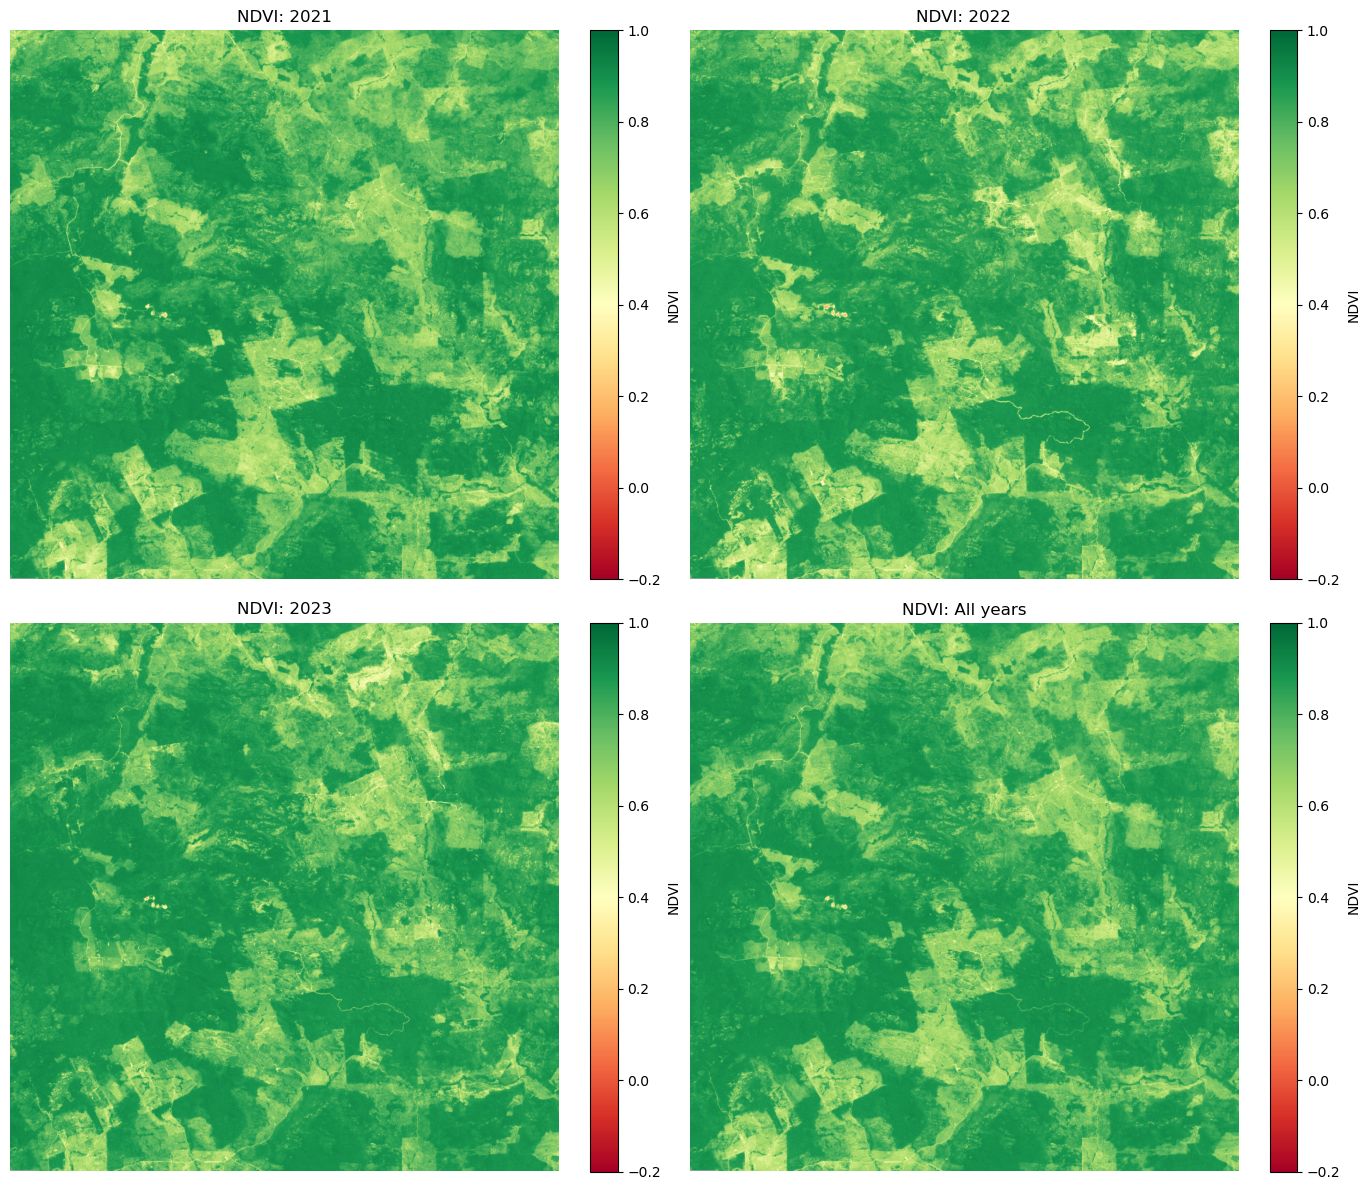

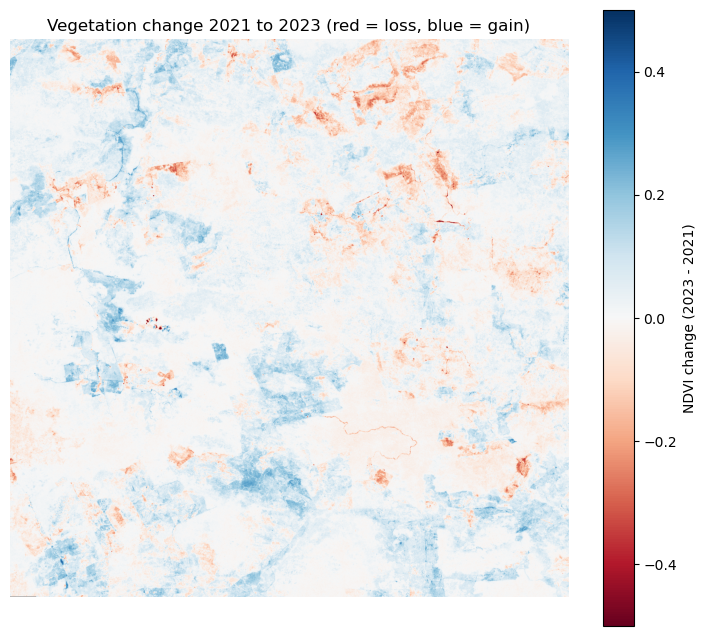

In [ ]:
def ndvi_of(arr):
    red, nir = arr[2], arr[3]
    with np.errstate(divide="ignore", invalid="ignore"):
        return (nir - red) / (nir + red)

ndvis = {name: ndvi_of(arr) for name, arr in composites.items()}

print(f"{'Period':<10} {'mean':>7} {'median':>7} {'p5':>7} {'p95':>7}")
for name, nd in ndvis.items():
    v = nd[np.isfinite(nd)]
    print(f"{name:<10} {v.mean():7.3f} {np.median(v):7.3f} "
          f"{np.percentile(v, 5):7.3f} {np.percentile(v, 95):7.3f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (name, nd) in zip(axes.ravel(), ndvis.items()):
    im = ax.imshow(nd[::STEP, ::STEP], cmap="RdYlGn", vmin=-0.2, vmax=1)
    ax.set_title(f"NDVI: {name}")
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, label="NDVI")
for ax in axes.ravel()[len(ndvis):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# change map: last year minus first year
if "2021" in ndvis and "2023" in ndvis:
    diff = ndvis["2023"] - ndvis["2021"]
    plt.figure(figsize=(9, 8))
    plt.imshow(diff[::STEP, ::STEP], cmap="RdBu", vmin=-0.5, vmax=0.5)
    plt.colorbar(label="NDVI change (2023 - 2021)")
    plt.title("Vegetation change 2021 to 2023 (red = loss, blue = gain)")
    plt.axis("off")
    plt.show()